# MLP

The MLP (MultiLayer Perceptron) or *feedforward neural network* is
Metis’s most basic architecture.

## When this might be a good fit

The MLP is a good starting point for datasets with only static inputs.
It is very fast to train and generate predictions from. It will likely
not outperform the other architectures (when properly tuned), and unlike
the Normalising Flow or Flow Matching architectures, the MLP is a
deterministc surrogate.

## How does an MLP work?

### Architectural walkthrough

An MLP’s computation is a series of matrix multiplications composed with
non-linear activations. Metis’s implementation also includes *residual*
connections which stablise the training of deeper networks.

In order to get a better sense of how these components work lets trace
through the network’s forward computation:

``` python
x = self.input_layer(inputs)
for block in self.blocks:
    x = block(x)
x = self.output_layer(x)
```

The input_layer linearly projects (i.e. a matrix multiplication) the
static input vector to vectors the size of the model’s hidden dimension.
Next, we iteratively pass our transformed inputs through a series of
residual blocks.

Each residual block applies several layers to the input and adds the
result back to the original input:

<figure>
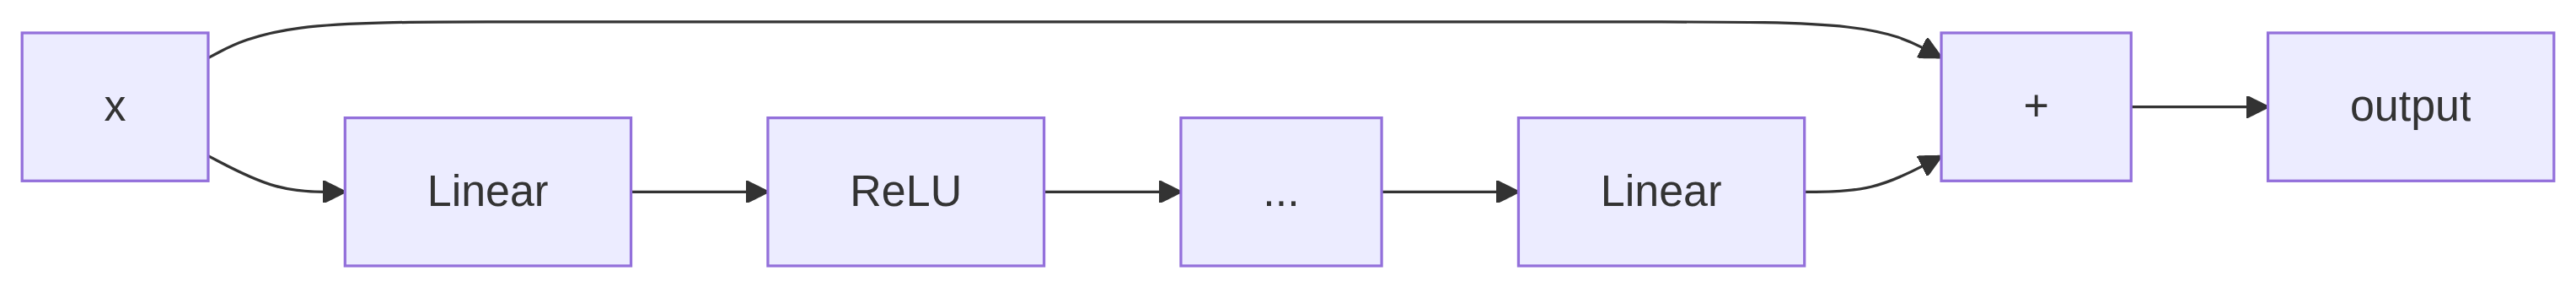
<figcaption aria-hidden="true">Residual block structure.</figcaption>
</figure>

Finally, the output layer linearly projects `x` to the output
dimensionality.

### Training

The MLP is trained to minimise the Mean-Squared Error:

$$
\mathrm{Loss} = \frac{1}{M}\sum_{m=1}^{M}(\mathrm{MLP}^{\theta}(\mathrm{static\_input}_m)-\mathrm{output}_m)^2
$$

## Configuring an MLP

The MLP’s architecture is configured via:

-   `input_dim`: The number of static inputs.
-   `output_dim`: The flattened dimensionality of the sequence. (e.g. 5
    timesteps where each step has 3 values would have a flat dim of 15)
-   `num_blocks`: The number of residual blocks in the network
    (i.e. network depth)
-   `hidden_dim`: The width of the network (all the matrices inside
    residual blocks will be
    $\mathrm{hidden\_dim}\times \mathrm{hidden\_dim}$)
-   `num_layers_per_block`: The number of layers within a residual block
    (also controls depth)

The first two options are automatically configured for the dataset that
you train on.

Within Metis we already provide MLP size presets:

| Config        | `hidden_dim` | `num_blocks` | `num_layers_per_block` |
|---------------|-------------:|-------------:|-----------------------:|
| `mlp_small`   |          128 |            5 |                      2 |
| `mlp_default` |          256 |           10 |                      2 |
| `mlp_large`   |          512 |           20 |                      3 |

To create a new MLP configuration in `configs/model`:

``` yaml
defaults:
  - mlp_default
  - _self_

num_blocks: ...
hidden_dim: ...
num_layers_per_block: ...
```